# Capital Management：Kelly 准则

本 notebook 对应 Hilpisch《Python for Algorithmic Trading》第 10 章 Capital Management 一节，用书中设定复现图 10-1 至 10-3。公式推导、几何平均与分数 Kelly 见前置文章《Kelly 准则及其在仓位管理中的应用》，此处只交代仿真参数与实现假设。


## 1. 二项设定：掷硬币仿真

偶数赔率，$p=0.55$，因而 $f^*=p-q=0.1$。初始资本 100；50 条路径，每条 100 局。赢则资本乘 $1+f$，输则乘 $1-f$。


In [1]:
import math
import numpy as np
import pandas as pd
import datetime as dt
from pylab import plt, mpl

np.random.seed(1000)
plt.style.use("seaborn-v0_8")
mpl.rcParams["savefig.dpi"] = 300
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.serif"] = ["Noto Serif CJK SC", "DejaVu Serif"]
mpl.rcParams["axes.unicode_minus"] = False


In [2]:
p = 0.55                          # ① 正面概率
f = p - (1 - p)                   # ② Kelly 最优比例 f* = p - q
print("f* =", f)                  # 书中 Out[5] ≈ 0.1

f* = 0.10000000000000009


In [3]:
n_paths = 50   # 路径条数
n = 100        # 每条路径的局数；财富时点比局数多 1 个本金时点

In [4]:
def run_simulation(f):
    """n_paths 条路径、每条 n 局；返回形状 (n+1, n_paths)，第 0 行是本金。"""
    win = np.random.random((n, n_paths)) < p  # 行是局，列是路径
    factor = np.where(win, 1 + f, 1 - f)
    c = np.empty((n + 1, n_paths))
    c[0] = 100
    c[1:] = 100 * np.cumprod(factor, axis=0)
    return c


def path_geomean(c):
    """各时点跨路径几何平均：exp(mean(log c))，对齐 Kelly 的 E[log c]。"""
    return np.exp(np.log(c).mean(axis=1))


def path_arimean(c):
    """各时点跨路径算术平均：c.mean(axis=1)。书中 Figure 10-1/10-2 用此函数。"""
    return c.mean(axis=1)

In [5]:
c_1 = run_simulation(f)
print(c_1.round(2))              # 形状 (n+1, n_paths) = (101, 50)

[[100.   100.   100.   ... 100.   100.   100.  ]
 [ 90.   110.    90.   ... 110.   110.   110.  ]
 [ 81.   121.    81.   ... 121.   121.   121.  ]
 ...
 [203.72 111.58 203.72 ... 248.99 454.6  136.37]
 [224.09 122.73 183.34 ... 224.09 500.06 122.73]
 [246.5  135.01 201.68 ... 246.5  450.05 110.46]]


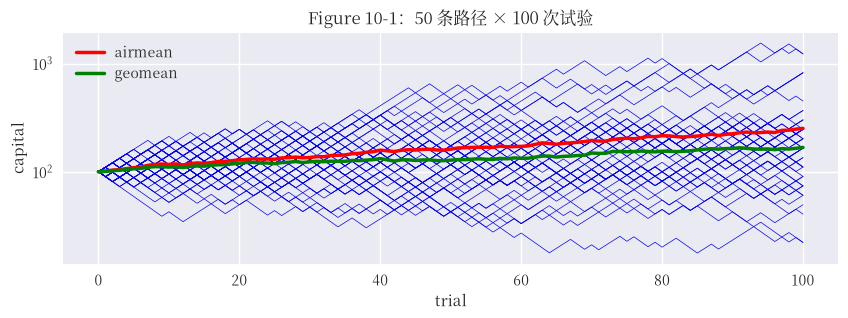

In [6]:
plt.figure(figsize=(10, 3))
plt.plot(c_1, "b", lw=0.5)                         # plot 50 条路径
plt.plot(path_arimean(c_1), "r", lw=2.5, label="airmean")           # 红线：算术平均
plt.plot(path_geomean(c_1), "g", lw=2.5, label="geomean")           # 绿线：几何平均
plt.title("Figure 10-1：50 条路径 × 100 次试验")
plt.xlabel("trial")
plt.ylabel("capital")
plt.yscale("log")
plt.legend()
plt.show()

再比较不同 $f$。过小则平均增长偏慢；过大（如 0.5）波动显著上升，期末表现甚至可能更差。


In [7]:
c_2 = run_simulation(0.05)   # ① f = 0.05（偏保守）
c_3 = run_simulation(0.25)   # ② f = 0.25（偏激进）
c_4 = run_simulation(0.5)    # ③ f = 0.5（过高）

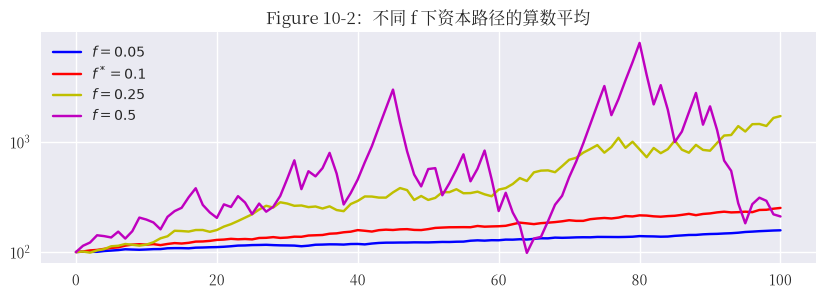

In [8]:
plt.figure(figsize=(10, 3))
# 书中写法：对各 f 画算术平均
plt.plot(path_arimean(c_2), "b", label="$f=0.05$")
plt.plot(path_arimean(c_1), "r", label="$f^*=0.1$")
plt.plot(path_arimean(c_3), "y", label="$f=0.25$")
plt.plot(path_arimean(c_4), "m", label="$f=0.5$")
plt.legend(loc=0)
plt.title("Figure 10-2：不同 f 下资本路径的算数平均")
plt.yscale("log")
plt.show()

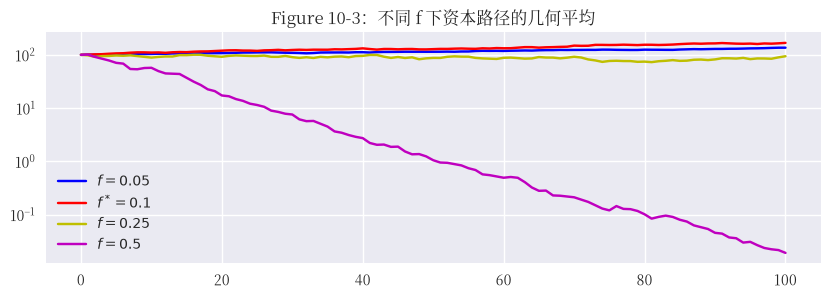

In [9]:
plt.figure(figsize=(10, 3))
plt.plot(path_geomean(c_2), "b", label="$f=0.05$")
plt.plot(path_geomean(c_1), "r", label="$f^*=0.1$")
plt.plot(path_geomean(c_3), "y", label="$f=0.25$")
plt.plot(path_geomean(c_4), "m", label="$f=0.5$")
plt.legend(loc=0)
plt.title("Figure 10-3：不同 f 下资本路径的几何平均")
plt.yscale("log")
plt.show()

书中 Figure 10-1 / 10-2 画的是跨路径算术平均。Kelly 优化的是 $\mathbb{E}[\ln c]$，应对齐几何平均 $\exp(\mathrm{mean}(\ln c))$，并用对数纵轴；算术平均会被少数幸运路径抬高，随 $f$ 单调上升，不能用来比较仓位。


## 2. 股票与股指上的 Kelly

连续近似下 $f^*=(\mu-r)/\sigma^2$。书中使用对数**日**收益估计**年化**：$\mu$ 为日均 $\times 252$，$\sigma$ 为日波动 $\times\sqrt{252}$，无风险利率取 $r=0$。 $f^*>1$ 表示杠杆。


### 2.1 实例：被动做多标普 500

读取书中 EOD 数据，由对数日收益估计年化 $\mu$，$\sigma$，再代入 $f^*$。数据源为 Hilpisch 提供的 CSV；若网络不可用，请自行下载到本地后改路径。


In [10]:
from pathlib import Path

_data_path = Path("data/pyalgo_eikon_eod_data.csv")
DATA_URL = str(_data_path) if _data_path.exists() else "http://hilpisch.com/pyalgo_eikon_eod_data.csv"
print("读取:", DATA_URL)

raw = pd.read_csv(DATA_URL, index_col=0, parse_dates=True)
symbol = ".SPX"
data = pd.DataFrame(raw[symbol])
data["return"] = np.log(data / data.shift(1))
data.dropna(inplace=True)
data.tail()
# 书中 Out[21] 末几行形如：
# 2019-12-31  3230.78  0.002942


读取: data/pyalgo_eikon_eod_data.csv


,.SPX,return
Date,,
2019-12-23,3224.01,0.000866
2019-12-24,3223.38,-0.000195
2019-12-27,3240.02,0.000034
2019-12-30,3221.29,-0.005798
2019-12-31,3230.78,0.002942


In [11]:
mu = data["return"].mean() * 252           # ① 年化收益
sigma = data["return"].std() * 252 ** 0.5  # ② 年化波动
r = 0.0                                    # ③ 无风险利率（示例中取 0）
f = (mu - r) / sigma ** 2                  # ④ Kelly 最优比例

print("mu    =", mu)       # 书中 ≈ 0.0999
print("sigma =", sigma)    # 书中 ≈ 0.1476
print("f*    =", f)        # 书中 ≈ 4.59
# 解读：每 1 美元权益，策略侧投入约 4.59 美元名义 → 杠杆约 4.59


mu    = 0.09992181916534204
sigma = 0.14761569775486563
f*    = 4.585590244019818


$f^*$ 随超额收益增大、随波动减小；本例 $f^*\approx 4.59$，即每 1 美元权益对应约 4.59 美元名义仓位。


### 2.2 按日调整杠杆的权益路径

初始权益为 1，名义资本为 $f$。每日先按策略收益更新名义资本，再把名义资本调回当前权益 $\times f$：亏则减名义、盈则加名义。图 10-3 对比指数本身与 half / 2/3 / full Kelly 下的权益。


In [12]:
equs = []


def kelly_strategy(f):
    """在 data 上按固定杠杆 f 模拟权益与名义资本路径。"""
    global equs
    equ = "equity_{:.2f}".format(f)
    equs.append(equ)
    cap = "capital_{:.2f}".format(f)
    data[equ] = 1.0                            # ① 初始权益 = 1（用 float，避免 int64 列无法 .loc 写入浮点）
    data[cap] = data[equ] * f                  # ② 初始名义 = 1 * f
    for i, t in enumerate(data.index[1:]):
        t_1 = data.index[i]                    # ③ 上一交易日
        # ④ 名义资本随当日收益复利
        data.loc[t, cap] = data[cap].loc[t_1] * math.exp(data["return"].loc[t])
        # ⑤ 权益 = 旧权益 + 名义资本当日盈亏
        data.loc[t, equ] = (
            data[cap].loc[t] - data[cap].loc[t_1] + data[equ].loc[t_1]
        )
        # ⑥ 按新权益与固定杠杆重设名义资本
        data.loc[t, cap] = data[equ].loc[t] * f


kelly_strategy(f * 0.5)   # half Kelly
kelly_strategy(f * 0.66)  # 约 2/3 Kelly
kelly_strategy(f)         # full Kelly

print(data[equs].tail())
# 书中 Out[34] 末行量级约：equity_2.29≈6.58, equity_3.03≈9.50, equity_4.59≈14.01


TypeError: Invalid value '1.0012507769116654' for dtype 'int64'

In [ ]:
ax = data["return"].cumsum().apply(np.exp).plot(figsize=(10, 6))
data[equs].plot(ax=ax, legend=True)
ax.set_title("Figure 10-3：标普 500 累计表现 vs 不同 f 下的权益")
plt.show()


### 2.3 Full Kelly 与 Half Kelly

图 10-3 中 full Kelly（约 4.59）波动很大。实务常用 half Kelly 降低回撤，代价是长期几何增长也可能低于满仓 Kelly。分数 Kelly 的理由见前置文章第六节。


## 3. 小结

书中掷硬币仿真取 $p=0.55$、$f^*=0.1$；标普 500 被动多头得到 $f^*>1$，须加杠杆，full Kelly 路径波动剧烈。比较不同 $f$ 时看几何平均，不要看算术平均。


## 4. 参考

- 《Kelly 准则及其在仓位管理中的应用》（前置文章）
- Yves Hilpisch, *Python for Algorithmic Trading*, Chapter 10, Capital Management.
- Thorp, E. O. (1997/2006). *The Kelly Criterion in Blackjack, Sports Betting, and the Stock Market*.
- Hung, J. (2010). *Betting with the Kelly Criterion*.
- 数据：`http://hilpisch.com/pyalgo_eikon_eod_data.csv`
